# Multi-City Weather Comparison + Best Time to Travel Predictor

This project uses 10 years (2015-2024) of historical daily weather data from 9 Indian cities.

**Goals**
1. Group cities with similar weather patterns into **clusters** (K-Means).
2. Predict, based on the user's preference (cool / warm / dry), whether a city is worth visiting in a given month (**Classification**).
3. Build a **Travel Comfort Index** and an interactive **Trip Planner**.

**Data source:** Open-Meteo Archive API (free, no API key)

**Folder structure**


## 1. Setup

This section imports the libraries, defines the configuration, and creates the folders.
The configuration covers the cities, date range, model features, and user preference rules.


In [2]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, silhouette_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# City: (latitude, longitude)
CITIES = {
    "Delhi": (28.61, 77.21),
    "Mumbai": (19.08, 72.88),
    "Bengaluru": (12.97, 77.59),
    "Kolkata": (22.57, 88.36),
    "Chennai": (13.08, 80.27),
    "Jaipur": (26.91, 75.79),
    "Shimla": (31.10, 77.17),
    "Goa": (15.50, 73.83),
    "Leh": (34.15, 77.58),
}

START_DATE = "2015-01-01"
END_DATE = "2024-12-31"
TRAIN_END_YEAR = 2022          # 2015-2022 for training, 2023-2024 for testing

RAW_PATH = "data/raw/weather_daily.csv"
MONTHLY_PATH = "data/processed/monthly.csv"
CLUSTER_PATH = "data/processed/climatology_clusters.csv"
MODEL_PATH = "models/classifiers.pkl"
METRICS_PATH = "reports/metrics.csv"

# Features: only past history + location + season
FEATURES = [
    "tavg_hist", "rain_total_hist", "rainy_days_hist", "wind_hist",
    "m_sin", "m_cos", "lat", "lon",
]

# preference: (min avg temp, max avg temp, max rainy days in a month)
PREFERENCES = {
    "cool": (14, 24, 6),
    "warm": (24, 32, 6),
    "dry": (15, 32, 2),
}

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

for folder in ["data/raw", "data/processed", "models", "reports"]:
    os.makedirs(folder, exist_ok=True)

print("Setup ready. Cities:", len(CITIES))


Setup ready. Cities: 9


## 2. Helper Functions

These functions are reused in later cells:
- `build_climatology`: the 10-year average for each city-month (a "typical year")
- `add_history_features`: builds features from **past years only**, which prevents data leakage
- `make_label`: the "worth visiting" rule (the target label)
- `comfort_index`: a 0-100 travel comfort score


In [3]:
HIST_COLS = ["tavg", "rain_total", "rainy_days", "wind"]


def build_climatology(monthly):
    """One row per city and month, averaged over all years."""
    clim = (
        monthly.groupby(["city", "lat", "lon", "month"], as_index=False)
        .agg(
            tavg=("tavg", "mean"),
            tmax=("tmax", "mean"),
            tmin=("tmin", "mean"),
            rain_total=("rain_total", "mean"),
            rainy_days=("rainy_days", "mean"),
            wind=("wind", "mean"),
        )
    )
    clim["temp_range"] = clim["tmax"] - clim["tmin"]
    clim["m_sin"] = np.sin(2 * np.pi * clim["month"] / 12)
    clim["m_cos"] = np.cos(2 * np.pi * clim["month"] / 12)
    for c in HIST_COLS:
        clim[c + "_hist"] = clim[c]
    return clim


def add_history_features(monthly):
    """Each row gets features from the average of PREVIOUS years only (no leakage)."""
    m = monthly.sort_values(["city", "month", "year"]).copy()
    for c in HIST_COLS:
        m[c + "_hist"] = m.groupby(["city", "month"])[c].transform(
            lambda s: s.shift(1).expanding().mean()
        )
    return m.dropna(subset=[c + "_hist" for c in HIST_COLS])


def make_label(df, lo, hi, max_rainy_days):
    """1 = good month to visit, 0 = not good."""
    return (df["tavg"].between(lo, hi) & (df["rainy_days"] <= max_rainy_days)).astype(int)


def comfort_index(df, w_temp=5, w_rain=3, w_wind=2):
    """
    Travel Comfort Index (0-100).
    - Temperature: best around 20-28 C, penalty outside that range
    - Rain: more rainy days means a lower score
    - Wind: penalty above 20 km/h
    """
    temp_score = (100 - 8 * np.maximum(0, np.abs(df["tavg"] - 24) - 4)).clip(0, 100)
    rain_score = 100 * (1 - (df["rainy_days"] / 15).clip(0, 1))
    wind_score = 100 * (1 - ((df["wind"] - 20) / 30).clip(0, 1))
    total = max(w_temp + w_rain + w_wind, 1)
    score = (w_temp * temp_score + w_rain * rain_score + w_wind * wind_score) / total
    return score.round(1)

print("Helper functions defined.")


Helper functions defined.


## 3. Data Collection (Open-Meteo API)

We fetch daily weather data for the 9 cities from the API.
Variables: mean, maximum, and minimum temperature, precipitation (rain), and maximum wind speed.

> An internet connection is required. This cell can take 1-2 minutes.


In [5]:
import time
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

API_URL = "https://archive-api.open-meteo.com/v1/archive"
DAILY_VARS = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "wind_speed_10m_max",
]
RENAME = {
    "time": "date",
    "temperature_2m_mean": "tmean",
    "temperature_2m_max": "tmax",
    "temperature_2m_min": "tmin",
    "precipitation_sum": "precip",
    "wind_speed_10m_max": "wind",
}

# Session with automatic retries and increasing wait time
session = requests.Session()
retry = Retry(total=5, backoff_factor=2,
              status_forcelist=[429, 500, 502, 503, 504],
              allowed_methods=["GET"])
session.mount("https://", HTTPAdapter(max_retries=retry))

# Smaller requests: 5 years at a time
DATE_CHUNKS = [("2015-01-01", "2019-12-31"), ("2020-01-01", "2024-12-31")]


def fetch_chunk(lat, lon, start, end, attempts=5):
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": start,
        "end_date": end,
        "daily": ",".join(DAILY_VARS),
        "timezone": "Asia/Kolkata",
    }
    for attempt in range(1, attempts + 1):
        try:
            r = session.get(API_URL, params=params, timeout=120)
            r.raise_for_status()
            return pd.DataFrame(r.json()["daily"])
        except (requests.exceptions.RequestException, ConnectionError) as e:
            wait = 10 * attempt
            print(f"   Attempt {attempt} failed ({type(e).__name__}). Retrying in {wait}s...")
            time.sleep(wait)
    raise RuntimeError(f"Failed after {attempts} attempts for {start} to {end}")


def fetch_city(name, lat, lon):
    cache_file = f"data/raw/{name}.csv"
    if os.path.exists(cache_file):                 # skip cities already downloaded
        print(f"{name}: loaded from cache")
        return pd.read_csv(cache_file)

    parts = []
    for start, end in DATE_CHUNKS:
        parts.append(fetch_chunk(lat, lon, start, end))
        time.sleep(3)                              # be polite to the free API
    df = pd.concat(parts, ignore_index=True).rename(columns=RENAME)
    df["city"], df["lat"], df["lon"] = name, lat, lon
    df.to_csv(cache_file, index=False)
    print(f"{name}: downloaded and cached")
    return df


frames = []
for name, (lat, lon) in CITIES.items():
    frames.append(fetch_city(name, lat, lon))
    time.sleep(5)                                  # pause between cities

raw = pd.concat(frames, ignore_index=True)
raw.to_csv(RAW_PATH, index=False)
print(f"Saved {len(raw)} rows to {RAW_PATH}")
raw.head()


Delhi: downloaded and cached
Mumbai: downloaded and cached
Bengaluru: downloaded and cached
Kolkata: downloaded and cached
Chennai: downloaded and cached
Jaipur: downloaded and cached
Shimla: downloaded and cached
Goa: downloaded and cached
Leh: downloaded and cached
Saved 32877 rows to data/raw/weather_daily.csv


,date,tmean,tmax,tmin,precip,wind,city,lat,lon
0,2015-01-01,16.3,21.4,12.0,0.0,8.9,Delhi,28.61,77.21
1,2015-01-02,15.2,17.2,14.2,4.2,11.2,Delhi,28.61,77.21
2,2015-01-03,15.6,17.9,14.0,0.1,9.0,Delhi,28.61,77.21
3,2015-01-04,14.4,19.1,10.5,0.0,13.5,Delhi,28.61,77.21
4,2015-01-05,14.3,20.7,9.6,0.0,27.0,Delhi,28.61,77.21


## 4. Preprocessing: Daily to Monthly

- Remove missing values
- Summarize each city for each year and month
- **Rainy day** = more than 2.5 mm of rain
- Build the temperature range and season features (sin/cos)

Season is encoded as sin and cos so that December and January are close to each other.


In [6]:
raw = pd.read_csv(RAW_PATH, parse_dates=["date"])
raw = raw.dropna(subset=["tmean", "tmax", "tmin", "precip", "wind"])

raw["year"] = raw["date"].dt.year
raw["month"] = raw["date"].dt.month
raw["rainy_day"] = (raw["precip"] >= 2.5).astype(int)

monthly = (
    raw.groupby(["city", "lat", "lon", "year", "month"], as_index=False)
    .agg(
        tavg=("tmean", "mean"),
        tmax=("tmax", "mean"),
        tmin=("tmin", "mean"),
        rain_total=("precip", "sum"),
        rainy_days=("rainy_day", "sum"),
        wind=("wind", "mean"),
    )
)
monthly["temp_range"] = monthly["tmax"] - monthly["tmin"]
monthly["m_sin"] = np.sin(2 * np.pi * monthly["month"] / 12)
monthly["m_cos"] = np.cos(2 * np.pi * monthly["month"] / 12)

monthly.to_csv(MONTHLY_PATH, index=False)
print(f"{len(monthly)} city-month-year rows saved")
monthly.head()


1080 city-month-year rows saved


,city,lat,lon,year,month,tavg,tmax,tmin,rain_total,rainy_days,wind,temp_range,m_sin,m_cos
0,Bengaluru,12.97,77.59,2015,1,20.758065,26.961290,15.425806,6.0,1,13.164516,11.535484,0.500000,8.660254e-01
1,Bengaluru,12.97,77.59,2015,2,22.321429,29.425000,15.564286,0.6,0,14.642857,13.860714,0.866025,5.000000e-01
2,Bengaluru,12.97,77.59,2015,3,24.987097,31.774194,18.567742,11.4,2,14.345161,13.206452,1.000000,6.123234e-17
3,Bengaluru,12.97,77.59,2015,4,25.366667,30.873333,20.620000,79.1,7,11.103333,10.253333,0.866025,-5.000000e-01
4,Bengaluru,12.97,77.59,2015,5,25.129032,30.735484,21.032258,157.6,14,12.609677,9.703226,0.500000,-8.660254e-01


## 5. EDA: Weather Patterns

These plots show:
- How each city's temperature changes over the year
- Which cities get the most rain, and in which months

These graphs will be used in the **Results** section of the report.


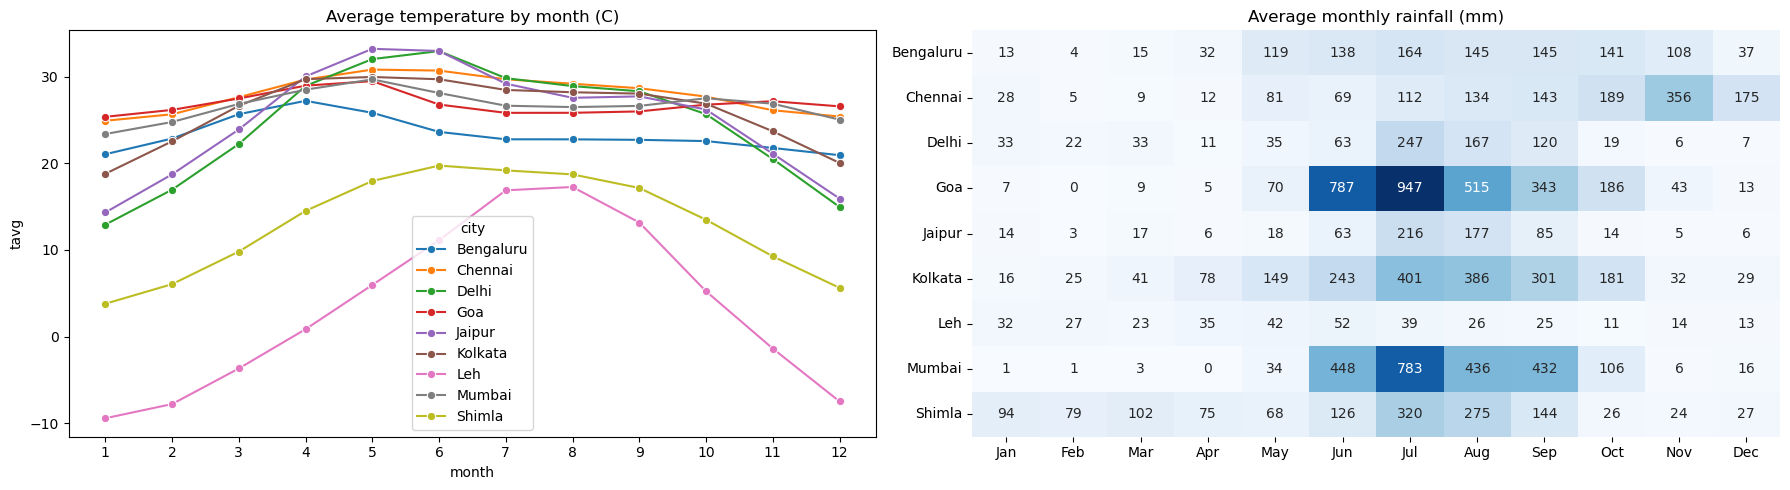

In [7]:
clim_eda = monthly.groupby(["city", "month"], as_index=False)[["tavg", "rain_total"]].mean()

fig, ax = plt.subplots(1, 2, figsize=(18, 5))

sns.lineplot(data=clim_eda, x="month", y="tavg", hue="city", marker="o", ax=ax[0])
ax[0].set_title("Average temperature by month (C)")
ax[0].set_xticks(range(1, 13))

rain_pivot = clim_eda.pivot(index="city", columns="month", values="rain_total")
rain_pivot.columns = MONTHS
sns.heatmap(rain_pivot.round(0), annot=True, fmt=".0f", cmap="Blues", ax=ax[1], cbar=False)
ax[1].set_title("Average monthly rainfall (mm)")
ax[1].set_xlabel("")
ax[1].set_ylabel("")

plt.tight_layout()
plt.show()


## 6. Clustering (K-Means)

**What we are doing:** We group 9 cities x 12 months = 108 rows into clusters based on weather features (temperature, rain, temperature range, and wind).

**How k was chosen:**
- **Elbow method:** look for the point where the inertia curve bends
- **Silhouette score:** higher means the clusters are more distinct and well separated

The final k = 4. Check the plot yourself to confirm this choice.


k=2  inertia=265.51  silhouette=0.361
k=3  inertia=169.19  silhouette=0.397
k=4  inertia=124.49  silhouette=0.348
k=5  inertia=97.76  silhouette=0.349
k=6  inertia=79.98  silhouette=0.340
k=7  inertia=66.22  silhouette=0.364


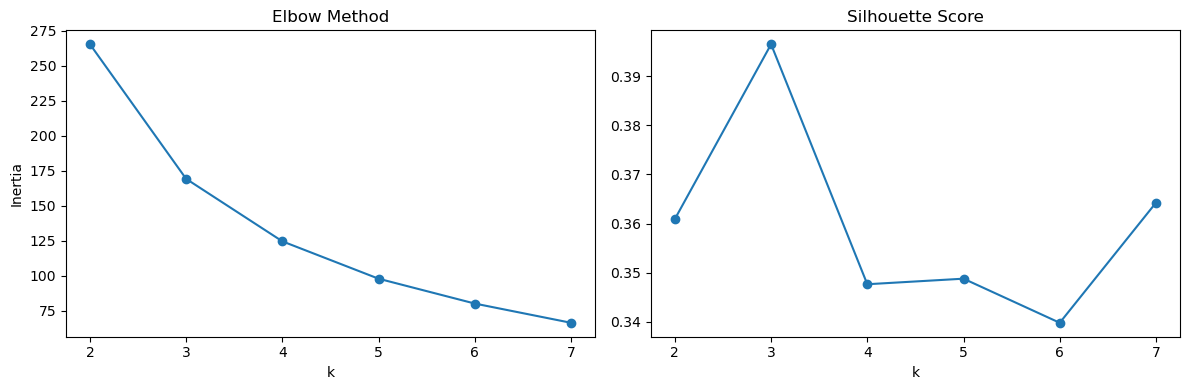

In [8]:
clim = build_climatology(monthly)            # 108 rows
CLUSTER_COLS = ["tavg", "rain_total", "temp_range", "wind"]
X = StandardScaler().fit_transform(clim[CLUSTER_COLS])

# Selecting k
ks = list(range(2, 8))
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    print(f"k={k}  inertia={km.inertia_:.2f}  silhouette={sil[-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertia")
ax[1].plot(ks, sil, marker="o")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("k")
plt.tight_layout()
fig.savefig("reports/k_selection.png", dpi=120, bbox_inches="tight")
plt.show()


### Final clustering and naming the clusters

Each cluster is given a readable name based on its average values, for example `Cold-Dry` or `Hot-Rainy`.


Cluster names: {0: 'Hot-Rainy', 1: 'Cold-Dry', 2: 'Pleasant-Dry', 3: 'Pleasant-Rainy'}


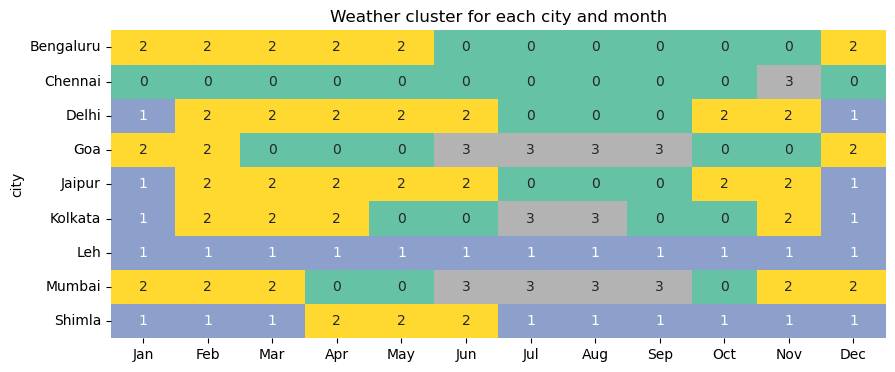

In [9]:
K = 4
km = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=10).fit(X)
clim["cluster"] = km.labels_


def name_cluster(sub):
    t = sub["tavg"].mean()
    r = sub["rain_total"].mean()
    temp = "Cold" if t < 18 else ("Pleasant" if t <= 27 else "Hot")
    rain = "Rainy" if r >= 100 else "Dry"
    return f"{temp}-{rain}"


names = {c: name_cluster(g) for c, g in clim.groupby("cluster")}
clim["cluster_name"] = clim["cluster"].map(names)
clim.to_csv(CLUSTER_PATH, index=False)

print("Cluster names:", names)

# Heatmap showing the cluster for each city and month
cluster_pivot = clim.pivot(index="city", columns="month", values="cluster")
cluster_pivot.columns = MONTHS
plt.figure(figsize=(10, 4))
sns.heatmap(cluster_pivot, annot=True, fmt=".0f", cmap="Set2", cbar=False)
plt.title("Weather cluster for each city and month")
plt.show()


## 7. Travel Comfort Index

This is the **original feature** of the project. It combines temperature, rainy days, and wind using weights to produce a 0-100 score.

You can change the weights to see how the score responds.


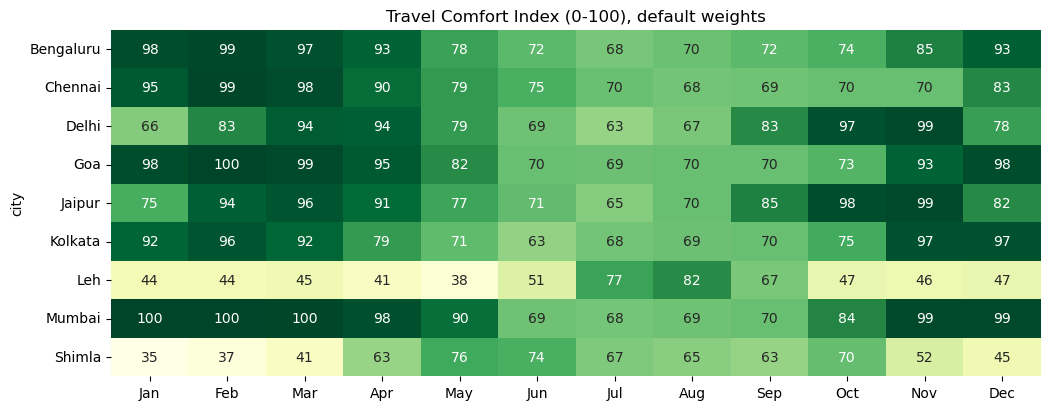

In [10]:
clim["comfort"] = comfort_index(clim, w_temp=5, w_rain=3, w_wind=2)

comfort_pivot = clim.pivot(index="city", columns="month", values="comfort")
comfort_pivot.columns = MONTHS
plt.figure(figsize=(12, 4.5))
sns.heatmap(comfort_pivot, annot=True, fmt=".0f", cmap="YlGn", cbar=False)
plt.title("Travel Comfort Index (0-100), default weights")
plt.show()


## 8. Classification: "Is this a good time to visit?"

**Label:** A rule based on the user's preference.
Example: for "cool", the average temperature is between 14 and 24 C and there are at most 6 rainy days.

**Features:** Only **past years'** history (no leakage).

**Split:** Time-based. 2015-2022 for training, 2023-2024 for testing. The model predicts the future from the past.

**Models compared:**
1. **Baseline** (DummyClassifier): always predicts the most common class
2. **Logistic Regression**
3. **Random Forest** (final model)


In [11]:
m = add_history_features(monthly)
train = m[m["year"] <= TRAIN_END_YEAR]
test = m[m["year"] > TRAIN_END_YEAR]
print(f"Train rows: {len(train)} | Test rows: {len(test)}")


def get_candidates():
    """New model instances for each preference."""
    return {
        "Baseline": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=1000, class_weight="balanced")),
        "RandomForest": RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            class_weight="balanced", random_state=RANDOM_STATE),
    }


rows, final_models = [], {}
for pref, (lo, hi, max_rain) in PREFERENCES.items():
    y_tr = make_label(train, lo, hi, max_rain)
    y_te = make_label(test, lo, hi, max_rain)

    for name, clf in get_candidates().items():
        clf.fit(train[FEATURES], y_tr)
        pred = clf.predict(test[FEATURES])
        rows.append({
            "preference": pref,
            "model": name,
            "accuracy": round(accuracy_score(y_te, pred), 3),
            "precision": round(precision_score(y_te, pred, zero_division=0), 3),
            "recall": round(recall_score(y_te, pred, zero_division=0), 3),
            "f1": round(f1_score(y_te, pred, zero_division=0), 3),
        })
        if name == "RandomForest":
            final_models[pref] = clf

metrics = pd.DataFrame(rows)
metrics.to_csv(METRICS_PATH, index=False)
joblib.dump(final_models, MODEL_PATH)
print(f"Models saved to {MODEL_PATH}")
metrics


Train rows: 756 | Test rows: 216
Models saved to models/classifiers.pkl


,preference,model,accuracy,precision,recall,f1
0,cool,Baseline,0.829,0.000,0.000,0.000
1,cool,LogisticRegression,0.755,0.392,0.784,0.523
2,cool,RandomForest,0.931,0.739,0.919,0.819
3,warm,Baseline,0.727,0.000,0.000,0.000
4,warm,LogisticRegression,0.861,0.699,0.864,0.773
5,warm,RandomForest,0.894,0.821,0.780,0.800
6,dry,Baseline,0.694,0.000,0.000,0.000
7,dry,LogisticRegression,0.880,0.738,0.939,0.827
8,dry,RandomForest,0.884,0.773,0.879,0.823


## 9. Feature Importance

This shows which features the Random Forest relies on most.
It is used for the **Explainability** part of the report.


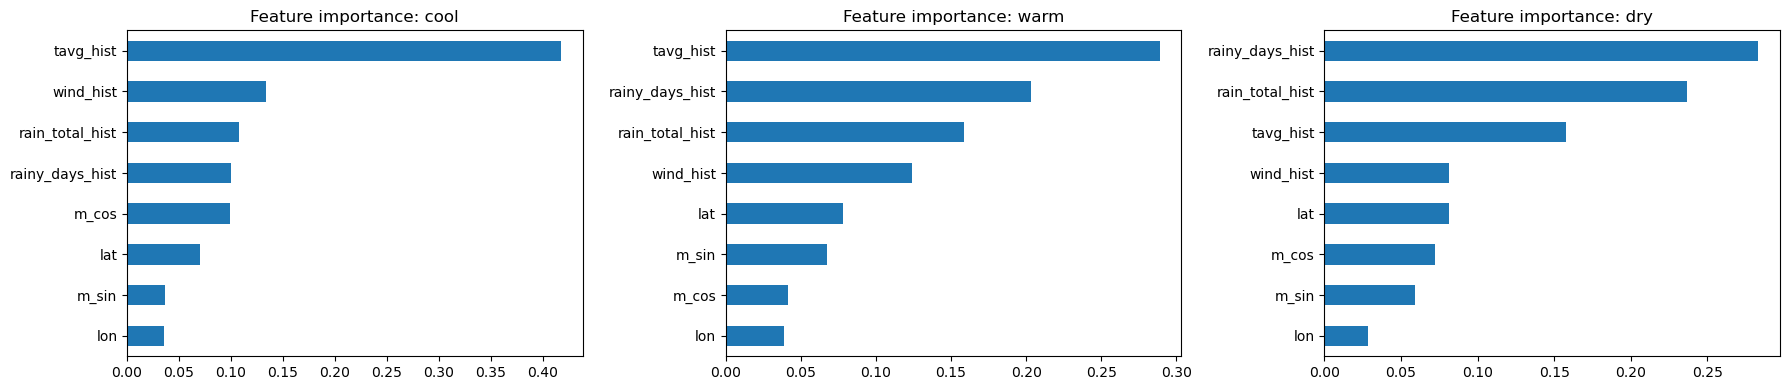

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (pref, rf) in zip(axes, final_models.items()):
    imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind="barh", ax=ax)
    ax.set_title(f"Feature importance: {pref}")
plt.tight_layout()
plt.show()


## 10. Trip Planner

The user selects a preference (cool / warm / dry) and comfort weights.
Output:
1. ML visit-probability heatmap
2. Comfort Index heatmap
3. Top 3 months for each city

> This cell reloads `clim` and `models` from files, so it still works after a kernel restart (as long as the earlier cells have been run once).


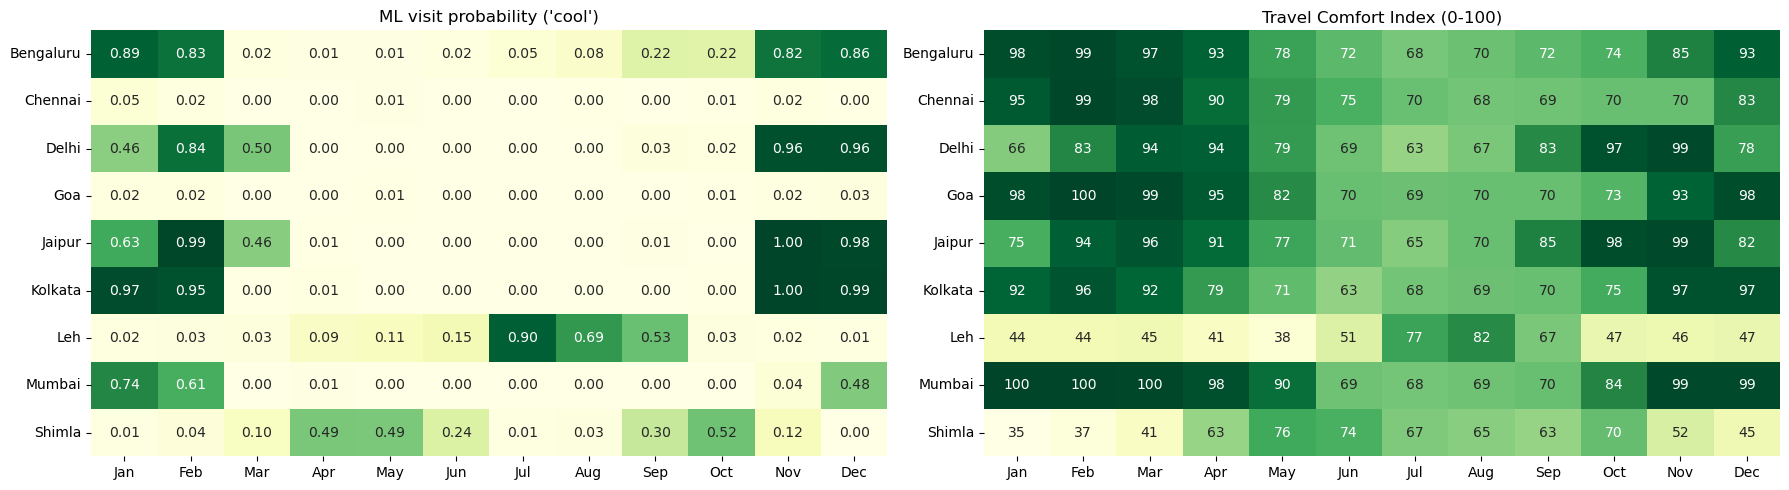

,city,Top 3 months
0,Bengaluru,"Feb, Jan, Mar"
1,Chennai,"Feb, Mar, Jan"
2,Delhi,"Nov, Oct, Mar"
3,Goa,"Feb, Mar, Jan"
4,Jaipur,"Nov, Oct, Mar"
5,Kolkata,"Nov, Dec, Feb"
6,Leh,"Aug, Jul, Sep"
7,Mumbai,"Feb, Jan, Mar"
8,Shimla,"May, Jun, Oct"


In [13]:
clim = pd.read_csv(CLUSTER_PATH)
models = joblib.load(MODEL_PATH)


def plan(pref="cool", w_temp=5, w_rain=3, w_wind=2):
    d = clim.copy()

    # ML: probability that the month is worth visiting
    classes = list(models[pref].classes_)
    if 1 in classes:
        d["ml_score"] = models[pref].predict_proba(d[FEATURES])[:, classes.index(1)]
    else:
        d["ml_score"] = 0.0
    d["comfort"] = comfort_index(d, w_temp, w_rain, w_wind)
    d["month_name"] = d["month"].map(lambda m: MONTHS[m - 1])

    # Heatmaps
    fig, axes = plt.subplots(1, 2, figsize=(18, 5))
    for ax, (col, title, fmt) in zip(axes, [
        ("ml_score", f"ML visit probability ('{pref}')", ".2f"),
        ("comfort", "Travel Comfort Index (0-100)", ".0f"),
    ]):
        pv = d.pivot(index="city", columns="month", values=col)
        pv.columns = MONTHS
        sns.heatmap(pv, annot=True, fmt=fmt, cmap="YlGn", ax=ax, cbar=False)
        ax.set_title(title)
        ax.set_xlabel("")
        ax.set_ylabel("")
    plt.tight_layout()
    plt.show()

    # Top 3 months for each city (by comfort score)
    top3 = (
        d.sort_values("comfort", ascending=False)
        .groupby("city")
        .head(3)
        .groupby("city")["month_name"]
        .apply(lambda s: ", ".join(s))
        .rename("Top 3 months")
        .reset_index()
    )
    return top3


plan("cool", 5, 3, 2)


In [14]:
# Interactive version (requires ipywidgets: pip install ipywidgets)
try:
    from ipywidgets import interact, IntSlider, Dropdown

    interact(
        plan,
        pref=Dropdown(options=list(PREFERENCES.keys()), value="cool", description="Preference"),
        w_temp=IntSlider(value=5, min=0, max=10, description="Temp weight"),
        w_rain=IntSlider(value=3, min=0, max=10, description="Rain weight"),
        w_wind=IntSlider(value=2, min=0, max=10, description="Wind weight"),
    )
except ImportError:
    print("Please install ipywidgets: pip install ipywidgets")


interactive(children=(Dropdown(description='Preference', options=('cool', 'warm', 'dry'), value='cool'), IntSl…

## 11. Conclusion and Limitations

**Conclusion**
- The 9 cities were grouped into 4 clusters based on their weather patterns.
- On the time-based split, Random Forest performed better than the baseline (see the metrics table).
- The Travel Comfort Index and the Trip Planner give users practical recommendations.

**Limitations**
- Open-Meteo data is **ERA5 reanalysis**, not exact ground-station readings, so rainfall is approximate.
- The labels are **rule-based** (comfort thresholds) and not taken from a survey.
- With only 9 cities, the clustering is limited.
- Crowd, price, and festival data are not included.

**Future scope**
- Add a live forecast (Open-Meteo Forecast API).
- Analyze monsoon onset and extreme heat or rain risk.
- Deploy the project as a Streamlit app.
